In [1]:
from pathlib import Path

import hdbscan
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print('Libraries loaded')

Libraries loaded


### Load CSV & Prepare features by imputing missing values with medians and standardising

In [2]:
panel = pd.read_csv("panel_cluster_ready.csv", parse_dates=["date"])
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]
X = panel[FEATURES].fillna(panel[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

In [3]:
panel["cluster"] = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5).fit_predict(X_scaled)
print(panel["cluster"].value_counts().sort_index())
print(f"noise: {(panel['cluster'] == -1).mean():.1%}")

cluster
-1     561
 0      35
 1      45
 2      31
 3     269
 4     132
 5      19
 6      22
 7      26
 8      49
 9      20
 10     40
 11     15
 12     29
 13     65
 14     32
 15     37
 16     16
 17     25
 18     55
 19     40
 20     52
 21     21
 22     47
 23     23
 24     44
Name: count, dtype: int64
noise: 32.1%


HDBSCAN creates 8 density-based clusters on 11 scaled features based on closeness in feature space. Each day gets a cluster label, or -1 (noise) if it doesn't fit any dense group.

A cluster needs at least 15 similar days to form a cluster (`min_cluster_size=15`), and each day is judged using its 5 nearest neighbours (`min_samples=15`).

### PCA plot coloured by cluster

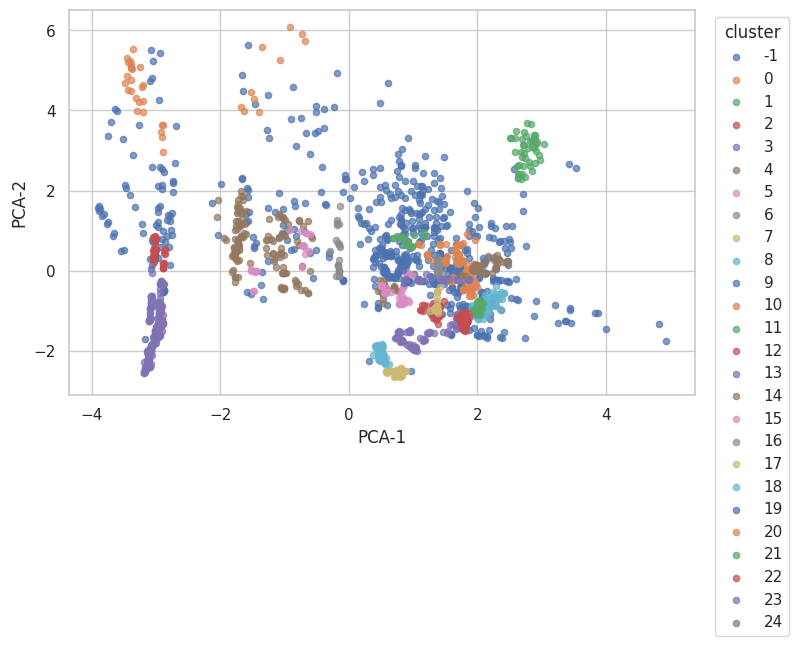

In [4]:
pca = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
panel["x"], panel["y"] = pca[:, 0], pca[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
for c in sorted(panel["cluster"].unique()):
    s = panel[panel["cluster"] == c]
    ax.scatter(s["x"], s["y"], label=c, alpha=0.7, s=20)
ax.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

- Cluster -1 (noise) is scattered around the middle & days in this cluster sit between groups or on the edges.
- Cluster 0 distinctively indicates low leverage and high distance_to_liq on the far left. Well separated from the looping whales.
- Cluster 1 sits at the top right with very high ltv, loop_depth, and carry_spread_levered - max leverage, well clear of the main cloud.
- Clusters 2 & 3 share the same high-leverage position on the right; cluster 2 sits on the upper band (fresher, ~1 month since rebalance) and cluster 3 on the lower band (staler, ~2.5 months) with no overlap between them.
- Cluster 4 sits at the bottom of the plot with high ltv but negative carry_spread - underwater on carry separate from the main looping group.
- Cluster 5 forms the largest block centre-right — typical active loop (ltv ~90%, moderate loop_depth) and the main bulk of the cloud.
- Cluster 6 sits in the centre, slightly above cluster 5 — same broad high-leverage region but with more frequent rebalancing (rebal_freq_7d).
- Cluster 7 sits left of centre with lower ltv and shallower loop_depth — more conservative looping, more buffer via distance_to_liq.


### PCA plot coloured by `whale_id`

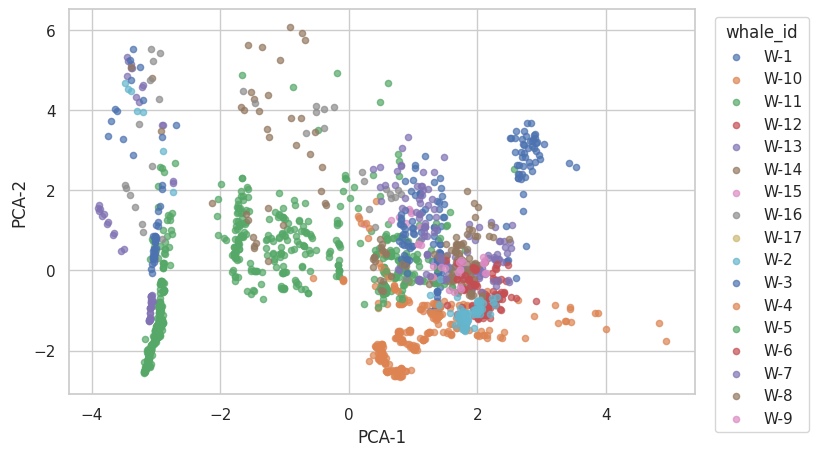

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for w in sorted(panel["whale_id"].unique()):
    s = panel[panel["whale_id"] == w]
    ax.scatter(s["x"], s["y"], label=w, alpha=0.7, s=20)
ax.legend(title="whale_id", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("PCA-1")
ax.set_ylabel("PCA-2")
fig.subplots_adjust(right=0.82)
plt.show()

This plot shows where each whale’s days sit in the same PCA space, so you can see how they spread across leverage and rebalancing or carry.

Whales with noise days span W-1..W-17; no whale is all-noise on this panel (W-17 has only 1 clusterable day).

W-3 is still the most versatile and spans the widest PCA area. W-11 (622 active days) dominates day count and pulls the balanced fit; W-10 and W-13 add long high-LTV stretches.

Most other whales sit in tighter patches, which is why baseline clustering often lines up with who is trading rather than a shared strategy type.

In [6]:
panel.groupby("cluster")[FEATURES].mean().round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
cluster,,,,,,,,,,,
-1,0.678,7.160,0.240,0.021,0.055,1.975,5.988,7.654,0.667,9.375,56.458
0,0.166,0.771,0.799,0.399,0.352,2.314,5.914,1.514,0.889,3.292,2.313
1,0.958,24.022,0.007,0.000,0.001,5.111,18.867,0.444,0.959,3.687,88.607
2,0.000,0.000,0.931,0.000,0.000,1.452,9.065,2.839,0.000,3.359,0.000
3,0.000,0.000,0.872,0.000,0.000,0.000,0.799,71.643,0.000,4.903,0.000
4,0.331,1.477,0.529,0.009,0.020,1.795,8.182,3.106,0.354,9.683,14.215
5,0.330,1.579,0.530,0.002,0.002,1.684,8.316,3.000,0.333,24.689,39.569
6,0.650,3.000,0.210,0.003,0.015,0.773,8.955,7.364,0.658,3.655,10.966
7,0.825,6.000,0.090,0.001,0.001,0.000,0.000,195.423,0.826,10.313,61.875


Untuned HDBSCAN still finds interpretable risk states (flap, max loop, stale, negative carry, active rebal, etc) but:
- there are too many clusters (8 + noise) for clean archetypes on 1,750 days.
- a large share of days land in cluster -1 (noise).
- several micro-clusters are dominated by one whale (W-11 in particular).

`03_balanced_clustering.ipynb` balances whales, tunes `min_cluster_size`, and assigns centroids for 3–4 cross-whale archetypes.